Project folder: D:\Skill Nexis- Intern\skill-nexis-internship\Week 3- Iris Flower Clustering

First five rows:
   sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)  \
0                5.1               3.5                1.4               0.2   
1                4.9               3.0                1.4               0.2   
2                4.7               3.2                1.3               0.2   
3                4.6               3.1                1.5               0.2   
4                5.0               3.6                1.4               0.2   

  Actual_Species  
0         setosa  
1         setosa  
2         setosa  
3         setosa  
4         setosa  

Dataset shape: (150, 4)

Missing values:
sepal length (cm)    0
sepal width (cm)     0
petal length (cm)    0
petal width (cm)     0
dtype: int64

Actual species counts:
Actual_Species
setosa        50
versicolor    50
virginica     50
Name: count, dtype: int64

Feature scaling completed.


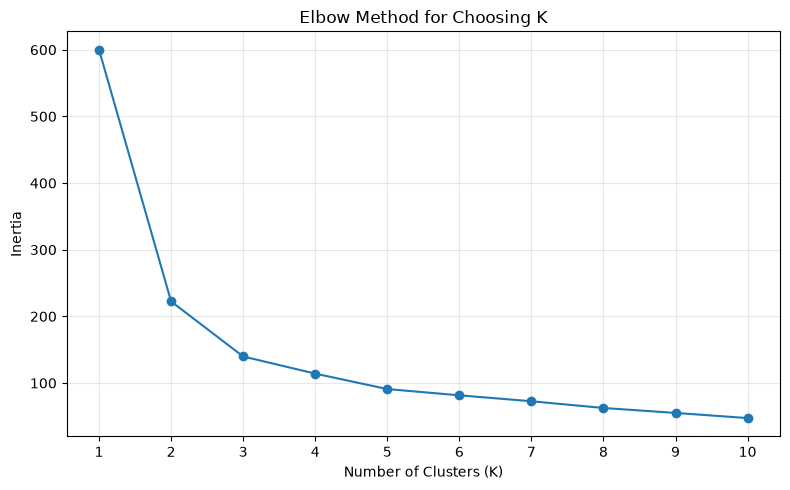


K-Means clustering completed.
Number of clusters: 3
Silhouette score: 0.4599

PCA completed.
Variance explained by PC1: 72.96 %
Variance explained by PC2: 22.85 %
Total variance explained: 95.81 %


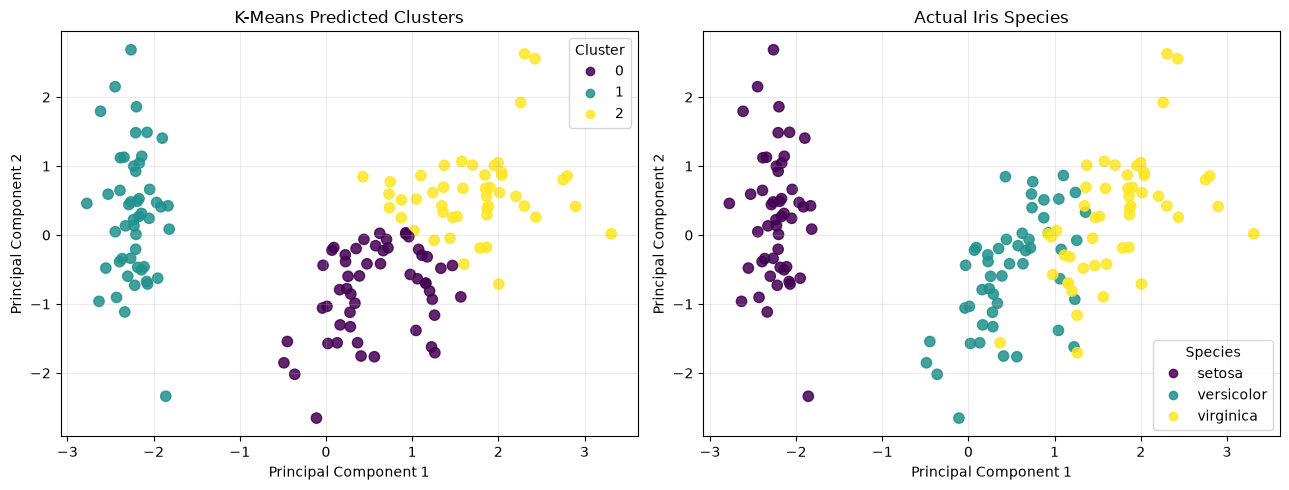


Actual Species vs Predicted Clusters:
Predicted Cluster   0   1   2
setosa              0  50   0
versicolor         39   0  11
virginica          14   0  36

Adjusted Rand Index (ARI): 0.6201

Model reload test passed: True

PROJECT SUMMARY
------------------------------
Dataset samples: 150
Input features: 4
Clusters created: 3
PCA components: 2
Adjusted Rand Index: 0.6201

Generated files:
- iris_clustering_results.csv
- iris_clusters_pca.png
- elbow_method.png
- kmeans_iris_model.joblib


In [1]:

# Week 3: Iris Flower Clustering Project
# Skill Nexis Machine Learning Internship

from pathlib import Path

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_iris
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import (
    adjusted_rand_score,
    silhouette_score,
    confusion_matrix
)

# --------------------------------------------------
# 1. Set the output folder
# --------------------------------------------------

OUTPUT_DIR = Path.cwd()
print("Project folder:", OUTPUT_DIR.resolve())

# --------------------------------------------------
# 2. Load and explore the Iris dataset
# --------------------------------------------------

iris = load_iris(as_frame=True)

X = iris.data.copy()
y = iris.target.copy()

feature_names = list(X.columns)
species_names = list(iris.target_names)

df = X.copy()
df["Actual_Species"] = y.map(
    dict(enumerate(species_names))
)

print("\nFirst five rows:")
print(df.head())

print("\nDataset shape:", X.shape)
print("\nMissing values:")
print(X.isnull().sum())

print("\nActual species counts:")
print(df["Actual_Species"].value_counts())

# --------------------------------------------------
# 3. Scale the numerical features
# --------------------------------------------------

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print("\nFeature scaling completed.")

# --------------------------------------------------
# 4. Elbow method: test different values of K
# --------------------------------------------------

inertias = []
k_values = range(1, 11)

for k in k_values:
    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )
    model.fit(X_scaled)
    inertias.append(model.inertia_)

plt.figure(figsize=(8, 5))
plt.plot(list(k_values), inertias, marker="o")
plt.title("Elbow Method for Choosing K")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Inertia")
plt.xticks(list(k_values))
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig(
    OUTPUT_DIR / "elbow_method.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

# --------------------------------------------------
# 5. Apply K-Means with K = 3
# --------------------------------------------------

kmeans = KMeans(
    n_clusters=3,
    random_state=42,
    n_init=10
)

predicted_clusters = kmeans.fit_predict(X_scaled)

print("\nK-Means clustering completed.")
print("Number of clusters:", len(np.unique(predicted_clusters)))
print(
    "Silhouette score:",
    round(silhouette_score(X_scaled, predicted_clusters), 4)
)

# --------------------------------------------------
# 6. Apply PCA: reduce 4 features to 2 components
# --------------------------------------------------

pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

explained_variance = pca.explained_variance_ratio_

print("\nPCA completed.")
print(
    "Variance explained by PC1:",
    round(explained_variance[0] * 100, 2), "%"
)
print(
    "Variance explained by PC2:",
    round(explained_variance[1] * 100, 2), "%"
)
print(
    "Total variance explained:",
    round(explained_variance.sum() * 100, 2), "%"
)

# --------------------------------------------------
# 7. Visualize predicted clusters vs actual species
# --------------------------------------------------

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

cluster_plot = axes[0].scatter(
    X_pca[:, 0],
    X_pca[:, 1],
    c=predicted_clusters,
    cmap="viridis",
    s=55,
    alpha=0.85
)
axes[0].set_title("K-Means Predicted Clusters")
axes[0].set_xlabel("Principal Component 1")
axes[0].set_ylabel("Principal Component 2")
axes[0].legend(
    *cluster_plot.legend_elements(),
    title="Cluster"
)
axes[0].grid(True, alpha=0.25)

species_plot = axes[1].scatter(
    X_pca[:, 0],
    X_pca[:, 1],
    c=y,
    cmap="viridis",
    s=55,
    alpha=0.85
)
axes[1].set_title("Actual Iris Species")
axes[1].set_xlabel("Principal Component 1")
axes[1].set_ylabel("Principal Component 2")
axes[1].legend(
    handles=species_plot.legend_elements()[0],
    labels=species_names,
    title="Species"
)
axes[1].grid(True, alpha=0.25)

plt.tight_layout()
plt.savefig(
    OUTPUT_DIR / "iris_clusters_pca.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

# --------------------------------------------------
# 8. Compare clusters with actual labels
# --------------------------------------------------

comparison = pd.crosstab(
    pd.Series(y, name="Actual Species"),
    pd.Series(predicted_clusters, name="Predicted Cluster")
)

comparison.index = species_names

print("\nActual Species vs Predicted Clusters:")
print(comparison)

ari = adjusted_rand_score(y, predicted_clusters)
print("\nAdjusted Rand Index (ARI):", round(ari, 4))

# --------------------------------------------------
# 9. Save results to CSV
# --------------------------------------------------

results = X.copy()
results["Actual_Species"] = [
    species_names[i] for i in y
]
results["Predicted_Cluster"] = predicted_clusters
results["PCA_Component_1"] = X_pca[:, 0]
results["PCA_Component_2"] = X_pca[:, 1]

results.to_csv(
    OUTPUT_DIR / "iris_clustering_results.csv",
    index=False
)

# --------------------------------------------------
# 10. Save the trained model and scaler
# --------------------------------------------------

joblib.dump(
    {
        "scaler": scaler,
        "kmeans": kmeans,
        "pca": pca,
        "feature_names": feature_names,
        "species_names": species_names
    },
    OUTPUT_DIR / "kmeans_iris_model.joblib"
)

# --------------------------------------------------
# 11. Reload the model and test it
# --------------------------------------------------

saved_objects = joblib.load(
    OUTPUT_DIR / "kmeans_iris_model.joblib"
)

loaded_scaler = saved_objects["scaler"]
loaded_kmeans = saved_objects["kmeans"]

reloaded_predictions = loaded_kmeans.predict(
    loaded_scaler.transform(X)
)

print(
    "\nModel reload test passed:",
    np.array_equal(predicted_clusters, reloaded_predictions)
)

# --------------------------------------------------
# 12. Summary
# --------------------------------------------------

print("\nPROJECT SUMMARY")
print("------------------------------")
print("Dataset samples:", len(X))
print("Input features:", len(feature_names))
print("Clusters created:", len(np.unique(predicted_clusters)))
print("PCA components:", X_pca.shape[1])
print("Adjusted Rand Index:", round(ari, 4))
print("\nGenerated files:")
print("- iris_clustering_results.csv")
print("- iris_clusters_pca.png")
print("- elbow_method.png")
print("- kmeans_iris_model.joblib")
